# Syria fuel price: history and forecast

All logic lives in `fuel_forecast.py` (loading, features, backtest, forecast). This notebook only calls it and draws charts.
Data: `fuel_decisions.csv` + `fuel_decisions_extra.csv`, `fx_chart_estimates.csv`, `brent_monthly.csv` (EIA), `external_events.csv`.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import fuel_forecast as ff

dec = ff.load_decisions()        # one row per decision and product, in new SYP and USD, with FX, Brent and availability
pairs = ff.make_pairs(dec)       # consecutive free-market decisions of the same product since 2024-05
print(len(dec), "decisions,", len(pairs), "pairs")
dec.tail(8)[["date", "product", "tier", "syp_new", "buy_est", "usd", "brent_l1", "availability"]]

52 decisions, 19 pairs


,date,product,tier,syp_new,buy_est,usd,brent_l1,availability
44,2026-07-24,gasoline_90,unsubsidized,145.0,132.0,1.098485,85.40,limited
45,2026-07-28,gasoline_90,unsubsidized,142.0,132.0,1.075758,85.40,limited
46,2026-09-04,diesel,unsubsidized,125.0,136.3,0.917095,91.08,crisis
47,2026-09-04,gasoline_90,unsubsidized,147.0,136.3,1.078503,91.08,crisis
48,2026-09-04,gasoline_95,unsubsidized,152.0,136.3,1.115187,91.08,crisis
49,2026-09-12,gasoline_90,unsubsidized,185.0,136.3,1.357300,91.08,crisis
50,2026-09-13,diesel,unsubsidized,175.0,136.3,1.283933,91.08,crisis
51,2026-09-13,gasoline_95,unsubsidized,195.0,136.3,1.430668,91.08,crisis


## 1. History: dollar rate and fuel prices (new SYP, log scale)

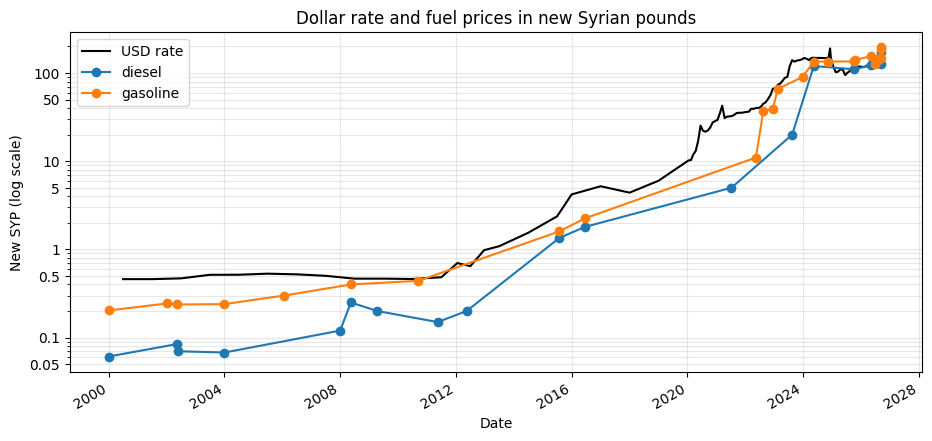

In [3]:
rate = ff.load_fx().set_index("date")["buy_est"].loc["2000":]
lines = dec.groupby(["date", "fuel"])["syp_new"].mean().unstack()

fig, ax = plt.subplots(figsize=(11, 5))
rate.plot(ax=ax, color="black", label="USD rate", logy=True)
for name in lines:
    lines[name].dropna().plot(ax=ax, marker="o", label=name)
ax.yaxis.set_major_formatter("{x:g}")
ax.set_yticks([0.05, 0.1, 0.5, 1, 5, 10, 50, 100])
ax.set(title="Dollar rate and fuel prices in new Syrian pounds", xlabel="Date", ylabel="New SYP (log scale)")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

## 2. Does Brent explain the Syrian price? (free-market gasoline 90, USD per litre)

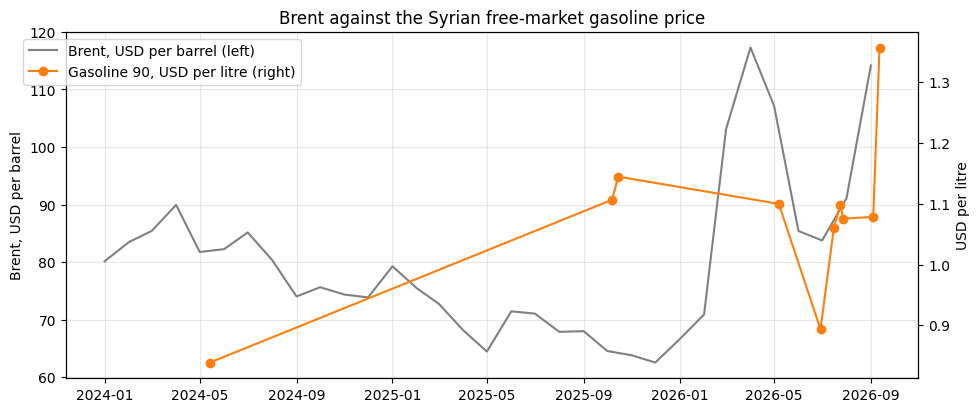

correlation of log prices: -0.26


In [4]:
g = dec[(dec["product"] == "gasoline_90") & (dec["tier"] == "unsubsidized") & (dec["date"] >= ff.MARKET_SINCE)]
brent = ff.load_brent().loc["2024-01":]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(brent.index, brent.values, color="gray", label="Brent, USD per barrel (left)")
ax.set_ylabel("Brent, USD per barrel")
ax2 = ax.twinx()
ax2.plot(g["date"], g["usd"], "o-", color="tab:orange", label="Gasoline 90, USD per litre (right)")
ax2.set_ylabel("USD per litre")
ax.set_title("Brent against the Syrian free-market gasoline price")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88))
ax.grid(alpha=0.3)
plt.show()
print("correlation of log prices:", round(np.log(g["usd"]).corr(np.log(g["brent_l1"])), 2))

## 3. Which model predicts the next decision best?

For every pair of consecutive decisions, each model predicts the log change of the price; training uses only pairs that
ended before the test pair started (expanding window). `typical_error` x1.16 means the price is about 16% off.

,n_tests,rmse_log,typical_error
back to usual USD level,13.0,0.145,1.157
Brent pass-through,13.0,0.152,1.164
"NeuralNet (8,4)",13.0,0.155,1.168
partial return (error correction),13.0,0.155,1.168
Ridge,13.0,0.157,1.170
price unchanged (SYP),13.0,0.157,1.170
price unchanged (USD),13.0,0.158,1.171
GradientBoosting,13.0,0.170,1.185


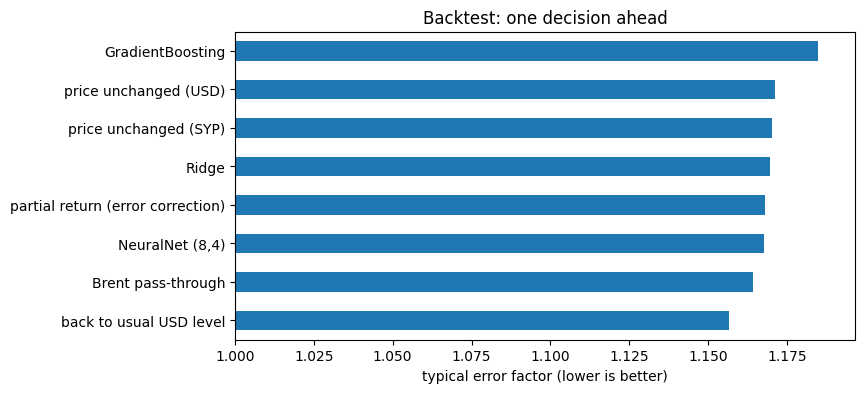

In [5]:
bt = ff.backtest(pairs)
display(bt.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
bt["typical_error"].sort_values().plot.barh(ax=ax, color="tab:blue")
ax.set(xlim=(1.0, bt["typical_error"].max() * 1.01), xlabel="typical error factor (lower is better)", title="Backtest: one decision ahead")
plt.show()

## 4. Forecast

The price is sticky in SYP (changes only at decisions, about 0.75 per month for gasoline 90) and each decision pulls it
partly back toward its usual USD level. The dollar rate is a random walk. Brent is not used (it did not help in the backtest).

In [6]:
params = ff.fit_process(pairs, dec)
print({k: (round(v, 3) if isinstance(v, float) else {a: round(b, 2) for a, b in v.items()}) for k, v in params.items() if k not in ("resid", "counts")})
print("monthly FX volatility:", round(ff.fx_volatility(), 3))

fc = ff.forecast(dec, params, months=6)
latest = dec[dec["tier"] == "unsubsidized"].sort_values("date").groupby("product").tail(1).set_index("product")
view = fc.pivot(index="month", columns="product", values=["syp_new_p10", "syp_new_p50", "syp_new_p90"]).round(0)
view.columns = [f"{p} {c.replace('syp_new_', '')}" for c, p in view.columns]
print("last observed (new SYP):", latest.loc[ff.PRODUCTS, "syp_new"].to_dict(), "on", latest["date"].max().date())
view

{'center': {'diesel': 0.94, 'gasoline_90': 1.1, 'gasoline_95': 1.19}, 'kappa': 0.5, 'sigma': 0.122, 'per_month': {'gasoline_90': 0.75, 'gasoline_95': 0.42, 'diesel': 0.33}}
monthly FX volatility: 0.05
last observed (new SYP): {'gasoline_90': 185.0, 'gasoline_95': 195.0, 'diesel': 175.0} on 2026-09-13


,diesel p10,gasoline_90 p10,gasoline_95 p10,diesel p50,gasoline_90 p50,gasoline_95 p50,diesel p90,gasoline_90 p90,gasoline_95 p90
month,,,,,,,,,
2026-11-01,144.0,147.0,167.0,175.0,185.0,195.0,175.0,187.0,195.0
2026-12-01,132.0,139.0,156.0,175.0,171.0,195.0,175.0,190.0,201.0
2027-01-01,126.0,133.0,151.0,164.0,165.0,191.0,175.0,192.0,205.0
2027-02-01,122.0,130.0,147.0,155.0,161.0,183.0,175.0,192.0,205.0
2027-03-01,119.0,128.0,145.0,150.0,159.0,179.0,175.0,195.0,207.0
2027-04-01,117.0,126.0,143.0,147.0,157.0,177.0,175.0,196.0,208.0


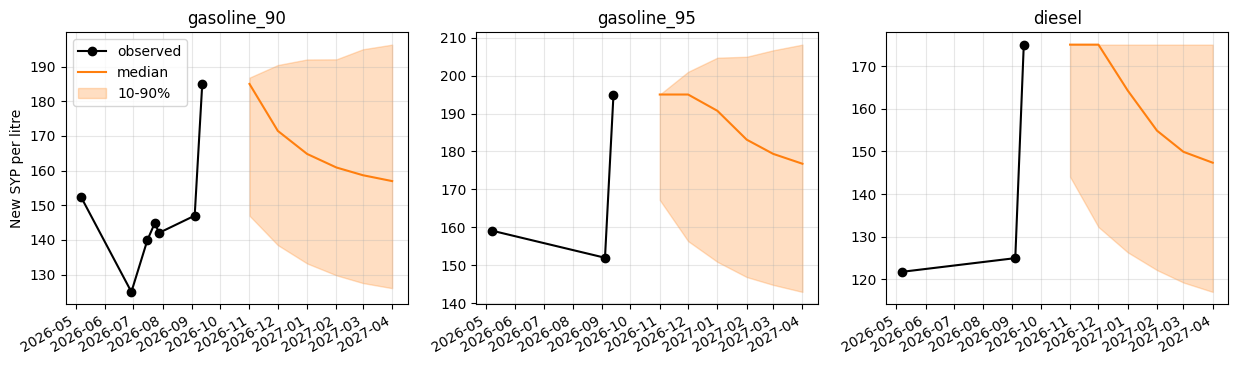

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, p in zip(axes, ff.PRODUCTS):
    hist = dec[(dec["product"] == p) & (dec["tier"] == "unsubsidized") & (dec["date"] >= "2026-01-01")]
    f = fc[fc["product"] == p]
    ax.plot(hist["date"], hist["syp_new"], "o-", color="black", label="observed")
    ax.plot(f["month"], f["syp_new_p50"], color="tab:orange", label="median")
    ax.fill_between(f["month"], f["syp_new_p10"], f["syp_new_p90"], alpha=0.25, color="tab:orange", label="10-90%")
    ax.set_title(p)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("New SYP per litre")
axes[0].legend()
fig.autofmt_xdate()
plt.show()

## 5. Scenarios for gasoline 90 in 6 months (median and 10-90% range, new SYP)

In [8]:
eia = ff.eia_brent_path()    # EIA 2026-10-06: Brent 105 in 4Q2026, 84 average in 2027
runs = {
    "base (FX flat, Brent ignored)": dict(),
    "FX weakens 10% in 6 months": dict(fx_drift=np.log(1.10) / 6),
    "FX strengthens 10% in 6 months": dict(fx_drift=np.log(0.90) / 6),
    "EIA Brent path, elasticity 0.3": dict(brent_path=eia, brent_elasticity=0.3),
}
rows = {}
for name, kw in runs.items():
    last = ff.forecast(dec, params, months=6, **kw).query("product == 'gasoline_90'").iloc[-1]
    rows[name] = {"p10": last["syp_new_p10"], "median": last["syp_new_p50"], "p90": last["syp_new_p90"], "median USD": last["usd_p50"]}
pd.DataFrame(rows).T.round(2)

,p10,median,p90,median USD
"base (FX flat, Brent ignored)",126.08,156.97,196.34,1.12
FX weakens 10% in 6 months,134.95,167.41,208.42,1.09
FX strengthens 10% in 6 months,116.74,146.37,184.18,1.16
"EIA Brent path, elasticity 0.3",122.65,153.31,191.01,1.09


In [9]:
fx0 = ff.load_fx()["buy_est"].iloc[-1]

for p in ff.PRODUCTS:
    current_syp = latest.loc[p, "syp_new"]
    current_usd = current_syp / fx0
    center = params["center"][p]
    gap = np.log(center) - np.log(current_usd)

    print(
        p,
        "current USD:", round(current_usd, 3),
        "center:", round(center, 3),
        "gap:", round(gap, 3),
        "expected correction:", round(params["kappa"] * gap, 3),
    )

gasoline_90 current USD: 1.326 center: 1.098 gap: -0.188 expected correction: -0.094
gasoline_95 current USD: 1.398 center: 1.194 gap: -0.158 expected correction: -0.079
diesel current USD: 1.254 center: 0.936 gap: -0.292 expected correction: -0.146


In [10]:
X = ff.features(
    pairs,
    params["center"]
)["gap"].values

y = pairs["y"].values

kappa_raw = (X * y).sum() / (X * X).sum()

print("Unconstrained kappa:", round(kappa_raw, 4))
print("Constrained kappa:", params["kappa"])

Unconstrained kappa: 0.5843
Constrained kappa: 0.5


In [11]:
for kappa in [0.2, 0.3, 0.4, 0.5, 0.5843]:
    err = pairs["y"].values - kappa * X
    rmse = np.sqrt(np.mean(err**2))
    print(f"kappa={kappa:.4f} | RMSE={rmse:.4f}")

kappa=0.2000 | RMSE=0.1276
kappa=0.3000 | RMSE=0.1256
kappa=0.4000 | RMSE=0.1241
kappa=0.5000 | RMSE=0.1232
kappa=0.5843 | RMSE=0.1230


## 6. What limits this forecast, and what data would help

- Only 19 consecutive-decision pairs exist for the free-market regime, so no model separates itself from "the price stays put".
- The decision log has holes (2013-2014, 2017-2020, most of 2023 and Nov 2025-Apr 2026). A complete log of dated price lists
  (Ministry of Internal Trade / Energy Ministry bulletins) would help most.
- The dollar rate is a chart estimate, not an official or parallel-market series by date.
- A monthly pump-price series from a price tracker would turn this into a normal time-series problem.